# 08L — Local Calibration และการเลือกวิธีตรวจ Anomaly

HT9046MX · การทดลองบนคอมเครื่องนี้ · 1 ตุลาคม 2026

คำถามของงานนี้คือ: **เมื่อเก็บเส้นอ้างอิงแยกรายเครื่องแล้ว การเพิ่ม ML ให้ประโยชน์กว่ากฎเดิมจริงหรือไม่?** Notebook นี้เล่าจากแหล่งข้อมูล ไปถึงความพร้อมของ Profile การเปรียบเทียบแบบใช้แถวเดียวกัน และกรณี MX057/M1 กับ MX080/M6 ที่เจ้าของโครงการยืนยันว่าเป็นพฤติกรรมผิดปกติแล้ว

ผลไม่ใช่การรับรองสาเหตุรั่วหรือ fault accuracy และไม่มีการเปลี่ยน Active Profile, MySQL หรือ Server. ในที่นี้ `Profile` ทุกชุดเป็น **offline train-only reference** ไม่ใช่ ACTIVE_FROZEN ของระบบใช้งานจริง.

## 1. เปิดผลที่รันแล้ว และวิธีรันซ้ำ

กราฟและตารางด้านล่างสร้างจากการทดลองที่รันจริง โดยมี source inventory และ SHA-256 กำกับ Notebook รันทุกเซลล์แล้ว แต่การเปิดอ่านไม่จำเป็นต้องเทรนซ้ำทุกครั้ง

บน Colab ให้วาง project checkout และโฟลเดอร์ผล `notebooks/outputs/local_profile_model_selection_v1` ใน Drive แล้วตั้ง `PROJECT_ROOT` ข้อมูล raw ไม่รวมใน Git: การ rebuild ต้องมี Parquet ต้นทาง และ cache ZIP ที่ได้จาก Notebook 08K ตาม protocol ไม่มีเซลล์เชื่อม MySQL หรือ approve Profile

คำสั่ง rebuild อยู่ท้าย notebook; ค่า path ของ source เปลี่ยนได้ผ่าน `--raw-root`. รูป PNG/SVG ถูกส่งออกไว้สำหรับสไลด์ด้วย

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display
from IPython import get_ipython
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p/'README_System.md').exists()), Path('/content/drive/MyDrive/OPERATION_P'))
if not (PROJECT_ROOT/'README_System.md').exists():
    raise FileNotFoundError('ตั้ง PROJECT_ROOT ให้ชี้ไปยัง project checkout บนเครื่องนี้หรือ Colab Drive')
sys.path.insert(0, str(PROJECT_ROOT))
from notebooks.support import local_profile_model_selection_presentation as viz
get_ipython().run_line_magic('matplotlib', 'inline')
OUT = PROJECT_ROOT/'notebooks/outputs/local_profile_model_selection_v1'
t = viz.tables(OUT)
print('Status:', t['summary']['status'])
print('Clock:', t['summary']['source_clock'])
print('Protocol SHA-256:', t['summary']['protocol_sha256'])
print('Selected primary:', t['summary']['decision'])

Status: SHADOW_ONLY_NOT_ACTIVE
Clock: naive source clock, interpreted as Asia/Bangkok for local review only
Protocol SHA-256: 45d8b131f827ed230f592df2b794228facfe6339300fa39faddb6c0008abf8e0
Selected primary: Keep local frozen robust-z + 3-adjacent-minute primary. ARX/DPCA/IF are non-voting comparison artifacts; improve reference qualification before any ML promotion.


## 2. ข้อมูลมาจากเครื่องไหน และใช้ทำอะไร

MX017, MX024, MX080 ใช้ daily dynamic TXT ที่อ่านจาก ZIP ทั้งห้าส่วนใน Downloads ผ่านตัวสร้าง strict-minute cache ของ 08K ส่วน MX029, MX041, MX057, MX070, MX118, MX119 อ่าน original raw-second Parquet ใหม่ **ไม่ใช้ `_Static.txt`** และไม่รวมแถวของเครื่องเดียวกันจากสอง source families ซ้ำกัน

ช่วงที่เลือกของรอบนี้คือ 4 ส.ค.–8 ก.ย. 2026; Parquet บางเครื่องสิ้นสุด 1 ก.ย. จึงมีระยะทดสอบไม่เท่ากัน MX118/MX119 มีวันไม่พอสร้าง Profile จึงเก็บเป็นตัวอย่าง abstention ไม่ใช้เทรนโมเดลกลาง ทุกเครื่องตรวจครบ Module 1–8 แม้บาง Module ไม่มี qualified Cold data

,machine,calendar_slots,observed_minutes,qualified_minutes,first_calendar_minute,last_calendar_minute
0,017,414720,403920,292896,2026-08-04,2026-09-08 23:59:00
1,024,414720,402128,234224,2026-08-04,2026-09-08 23:59:00
2,029,334080,312736,148504,2026-08-04,2026-09-01 23:59:00
3,041,334080,312536,270838,2026-08-04,2026-09-01 23:59:00
4,057,288000,267800,179805,2026-08-04,2026-09-01 23:59:00
5,070,288000,267432,214678,2026-08-04,2026-09-01 23:59:00
6,080,414720,404664,212062,2026-08-04,2026-09-08 23:59:00
7,118,46080,38992,34062,2026-08-17,2026-08-20 23:59:00
8,119,46080,38984,25296,2026-08-17,2026-08-20 23:59:00


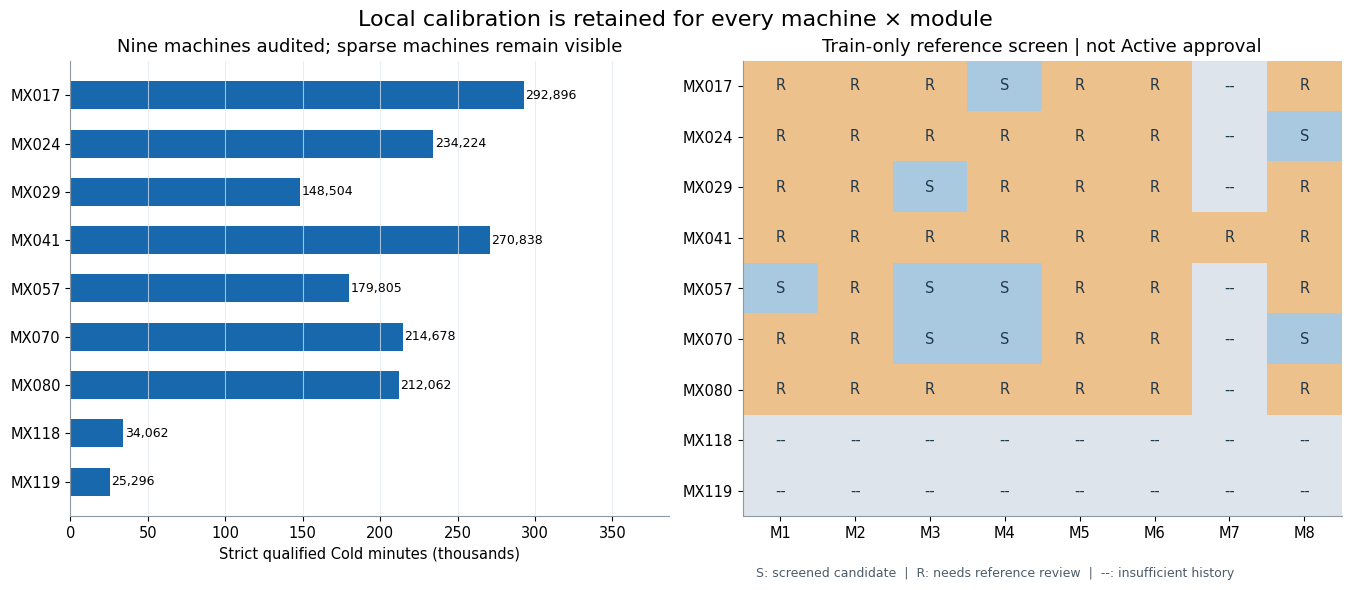

In [2]:
display(t['coverage'])
display(viz.source_and_reference(OUT))

อ่านกราฟ: S คือผ่าน screening เชิงสถิติสำหรับ candidate เท่านั้น ไม่ใช่ช่างยืนยันปกติ; R ต้องทบทวนช่วงอ้างอิง; -- วัน/นาทีไม่พอ ช่องว่างไม่ใช่ค่า Anomaly Score = 0 และไม่ควรแสดงสีเขียวว่าเครื่องปกติ

## 3. เส้นปกติและ Correlation จำเป็นต้องแยกรายเครื่องจริงไหม

แต่ละช่องซ้ายคือ median ของ Hp_2nd ในช่วง fit ของ Machine × Module นั้น ไม่ใช่ pressure target กลางของทั้ง fleet ขวาดูความสัมพันธ์ Lp_2nd กับ TempLo หลังลบ median รายวันเพื่อลดผลของคนละระดับ pressure ค่า Spearman ใกล้ +1 หมายถึงเคลื่อนทิศเดียวกัน ใกล้ −1 หมายถึงสวนทางกัน และใกล้ 0 หมายถึงความสัมพันธ์แบบอันดับไม่เด่น

การมี sign/strength ต่างกันสนับสนุนให้เก็บ local context แต่ correlation ไม่พิสูจน์เหตุ–ผล และอาจปน load, manual setting, startup หรือ sensor behavior ค่าช่องซ้ายยังเป็นเพียง candidate reference: ถ้าช่วง fit มีหลาย plateau การได้ median หนึ่งค่าก็ไม่ได้ทำให้ชุดนั้นเหมาะสำหรับ approve

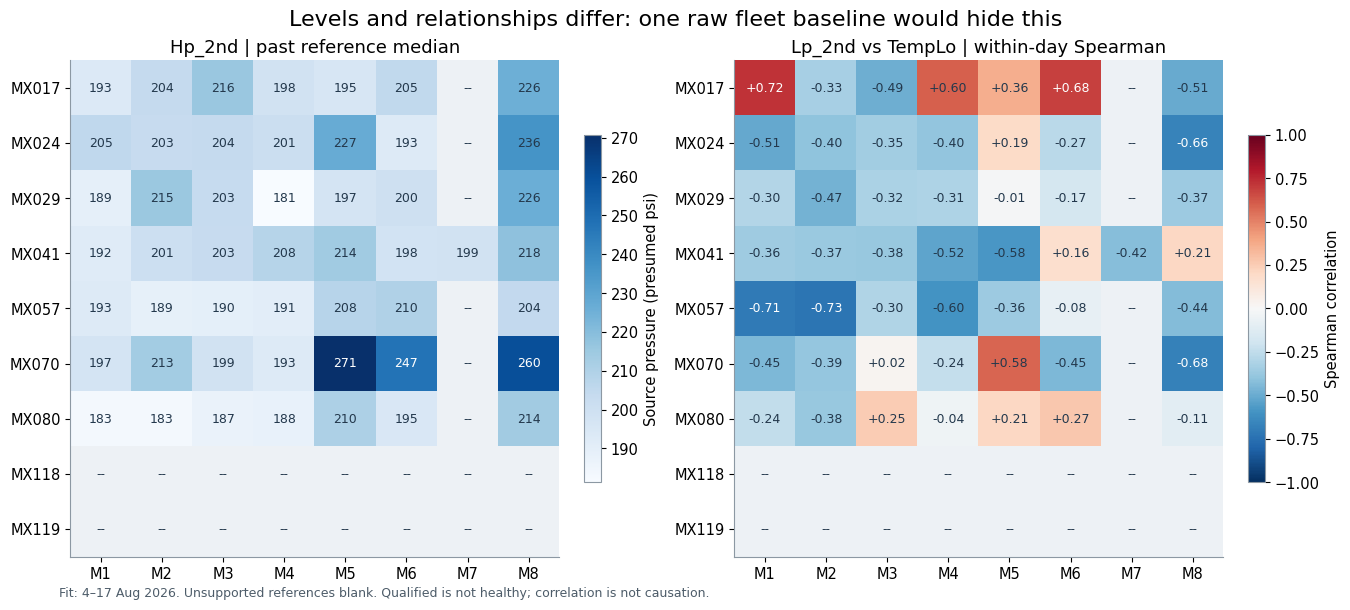

,machine,module,pair,rho,n
3,017,1,hp1/hp2,0.690918,12532
7,017,2,hp1/hp2,0.320425,12540
11,017,3,hp1/hp2,0.794000,12543
15,017,4,hp1/hp2,0.500283,12547
19,017,5,hp1/hp2,0.599301,12528
...,...,...,...,...,...
242,119,4,valve/lp2,-0.498414,1402
246,119,5,valve/lp2,-0.221797,1402
250,119,6,valve/lp2,-0.488856,1402
254,119,7,valve/lp2,0.509635,1402


In [3]:
display(viz.baseline_and_relationship(OUT))
display(t['correlations'].sort_values(['pair','machine','module']))

## 4. Auto-Calibration ในการทดลองนี้ทำอะไรบ้าง

เริ่มจาก raw ที่สังเกตได้จริง: ภายใน 1 นาทีต้องมีอย่างน้อย 57 จาก 60 second bins ไม่มี duplicate machine-second และ gap รวมขอบนาทีไม่เกิน 5 วินาที State ทั้งนาทีเป็น Run/On/Busy=0/SV=Off และ physical sensors ทั้งเจ็ด finite, Valve ไม่ติดลบ

Manual/ChangeValve/MValveHome และ SV/stop transition **ยังเก็บเป็น evidence** แต่ไม่ใส่ใน steady Cold baseline ตัวตรวจนี้ยังไม่ได้เรียนรู้ transition envelope และไม่มีการถือว่าระดับใหม่หลัง manual เป็นปกติโดยอัตโนมัติ

ฟีเจอร์ 9 ตัวคือ Hp1, Lp1, Hp2, Lp2, Valve, TempHi, TempLo และผลต่าง pressure สองวงจร:

$$dp_1=Hp_1-Lp_1,\qquad dp_2=Hp_2-Lp_2.$$

Profile ใช้เฉพาะ 4–17 ส.ค. และ fit 2 รอบ: รอบแรก quarantine แถวที่ $\max_j|z_j|>8$ จากนั้นคำนวณ median/scale อีกครั้ง **การ quarantine ไม่ใช่การยืนยัน healthy label**

$$m_j=\operatorname{median}(x_j),\qquad MAD_j=\operatorname{median}|x_j-m_j|$$
$$s_j=\max\left(1.4826MAD_j,\frac{Q_{.75,j}-Q_{.25,j}}{1.349},f_j\right),\qquad z_{t,j}=\frac{x_{t,j}-m_j}{s_j}.$$

$f_j=1$ count สำหรับ Valve และ 0.1 source unit สำหรับตัวอื่น ป้องกัน scale เป็นศูนย์/การขยับเพียงหนึ่ง command count กลายเป็น z สูงมาก ตัวเลขเหล่านี้สืบจาก contract ปัจจุบัน ไม่ได้ fit จากเคสที่ยืนยันแล้ว

ต้องเหลืออย่างน้อย 7 วันและ 200 นาทีหลัง quarantine การทดลองนี้เพิ่ม **reference screening** ว่า quarantine ไม่เกิน 5% และ median ครึ่งแรก–ครึ่งหลังต่างกันไม่เกิน 1.5 local z ชุดที่เกินยังแสดงใน diagnostic แต่ไม่ใช้เป็น shared-model fit data เกณฑ์นี้ไม่ใช่ change-point detector หรือสิทธิ์ approve

ขั้นในระบบจริงยังต้องเป็น Candidate → future 3-day Shadow → review/approval → ACTIVE_FROZEN การทดลองรอบนี้ **ไม่ได้ execute registry lifecycle นั้น** ไม่มีการย้าย offline reference ไป Active

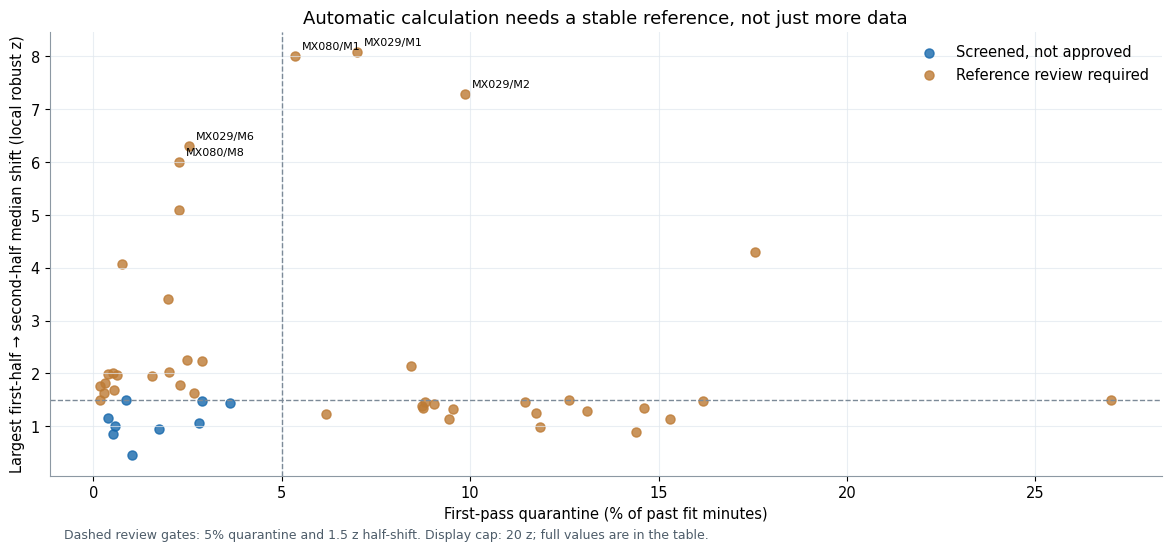

,machine,module,status,fit_days,fit_rows,retained_rows,quarantine_pct,max_half_shift_z
0,017,1,REFERENCE_REVIEW_REQUIRED,10,12532,10950.0,12.623683,1.489501
1,017,2,REFERENCE_REVIEW_REQUIRED,10,12540,11102.0,11.467305,1.461397
2,017,3,REFERENCE_REVIEW_REQUIRED,10,12543,12507.0,0.287013,1.622038
3,017,4,SCREENED_CANDIDATE_NOT_APPROVED,11,12547,12498.0,0.390532,1.155818
4,017,5,REFERENCE_REVIEW_REQUIRED,10,12528,12488.0,0.319285,1.822987
...,...,...,...,...,...,...,...,...
67,119,4,INSUFFICIENT_FIT,1,1402,NaN,NaN,NaN
68,119,5,INSUFFICIENT_FIT,1,1402,NaN,NaN,NaN
69,119,6,INSUFFICIENT_FIT,1,1402,NaN,NaN,NaN
70,119,7,INSUFFICIENT_FIT,1,1402,NaN,NaN,NaN


In [4]:
display(viz.reference_quality(OUT))
display(t['profiles'][['machine','module','status','fit_days','fit_rows','retained_rows','quarantine_pct','max_half_shift_z']])

### รู้เวลาหลังเริ่มทำงานจริงมากแค่ไหน

ตารางต่อไปนับเฉพาะ matched diagnostic future ที่มี offline reference ในรอบนี้ unknown onset ไม่ใช่ startup และเวลาเริ่มไฟล์ไม่ใช่เวลาเปิด compressor. เมื่อรู้ onset ยังต้องแยก run start, post-manual และ Cold control entry สัดส่วนเตือนตามอายุเป็น descriptive association ไม่ได้บอกว่า early flags ทุกจุดเป็น false alarms และไม่ได้ถูกใช้ตั้ง fixed suppression

In [5]:
phase=pd.read_csv(OUT/'phase_availability_diagnostic.csv',dtype={'machine':str})
phase_summary=phase.groupby('phase')[['rows','persistent_self']].sum()
phase_summary['flagged_pct']=100*phase_summary.persistent_self/phase_summary.rows
display(phase_summary)
print('Unknown onset (% matched future):',round(100*phase_summary.loc['UNKNOWN_ONSET','rows']/phase_summary.rows.sum(),2))

,rows,persistent_self,flagged_pct
phase,,,
OBSERVED_ENTRY_5_TO_20M,3877,1574,40.598401
OBSERVED_ENTRY_OVER_20M,72099,7208,9.997365
OBSERVED_ENTRY_UNDER_5M,1021,185,18.119491
UNKNOWN_ONSET,442030,61323,13.873040


Unknown onset (% matched future): 85.17


## 5. แยกข้อมูลตามเวลาและป้องกัน leakage

| ช่วง | หน้าที่ | ใช้กำหนดอะไร |
|---|---|---|
| 4–17 ส.ค. | Fit | Local reference, scaler, Ridge/PCA/IF weights |
| 18–21 ส.ค. | Inner validation | เลือก Ridge alpha ด้วย prediction MSE เฉลี่ยเท่ากันราย Profile |
| 22–25 ส.ค. | Past threshold block | Q99.5 ราย Machine × Module ต่อ lane ต้องมี ≥200 นาทีและ ≥3 วัน |
| 26 ส.ค.–8 ก.ย. | Diagnostic future | เปรียบเทียบผล ไม่ fit หรือปรับค่า |

ช่วงในตารางเป็น start-inclusive/end-exclusive ตาม protocol JSON การใช้ lag reset ทุกครั้งที่มี manual, state, missing-window หรือเปลี่ยนเครื่อง/โมดูล Training ไม่ใช้แถวที่ปัจจุบันหรือสอง lag ก่อนหน้าถูก quarantine

**ข้อจำกัดสำคัญ:** ข้อมูลและเคสบางส่วนถูกเปิดดูในงานก่อนแล้ว จึงไม่เรียกว่า untouched outer test หรือใช้ประกาศความแม่นยำ LOMO ในรอบนี้เป็น adapted LOMO: model weights ไม่เห็น held machine แต่ใช้ local profile และ threshold block จากอดีตของ held machine ได้ จึงไม่ใช่ zero-shot สำหรับเครื่องที่ไม่มีข้อมูลเลย

In [6]:
print(json.dumps(t['summary']['models'], indent=2))
display(pd.read_csv(OUT/'thresholds.csv', dtype={'machine':str}))

{
  "fit_rows": 22500,
  "inner_rows": 9000,
  "ridge_alpha": 100.0,
  "ridge_trials": [
    {
      "alpha": 0.1,
      "mean_profile_inner_mse": 0.0793591376360343
    },
    {
      "alpha": 1.0,
      "mean_profile_inner_mse": 0.07968508806968076
    },
    {
      "alpha": 10.0,
      "mean_profile_inner_mse": 0.07982833660232243
    },
    {
      "alpha": 100.0,
      "mean_profile_inner_mse": 0.0792213702605696
    }
  ],
  "dpca_components": 6,
  "dpca_explained_variance": 0.959368385091351,
  "fit_machines": [
    "017",
    "024",
    "029",
    "057",
    "070"
  ],
  "fit_profiles": 9
}


,machine,module,calibration_rows,calibration_days,self_legacy_threshold,self_separate_threshold,arx_threshold,dpca_threshold,iforest_threshold,status
0,017,1,4724,4,5.396000,8.094000,18.972781,9.184582,0.618267,CALIBRATED_SHADOW_ONLY
1,017,2,4741,4,9.296648,37.918567,231.478477,422.265269,0.606567,CALIBRATED_SHADOW_ONLY
2,017,3,4724,4,3.699393,8.000000,17.055441,7.671932,0.711515,CALIBRATED_SHADOW_ONLY
3,017,4,4741,4,4.773573,35.104836,160.181454,235.806149,0.723307,CALIBRATED_SHADOW_ONLY
4,017,5,4787,4,4.653963,2.768472,4.058087,1.165386,0.453392,CALIBRATED_SHADOW_ONLY
5,017,6,4788,4,6.773962,40.436963,57.700260,45.408032,0.636743,CALIBRATED_SHADOW_ONLY
6,017,8,4791,4,3.785808,2.982692,15.278702,7.674113,0.452972,CALIBRATED_SHADOW_ONLY
7,024,1,2894,3,8.067406,18.789269,35.258378,126.854247,0.716230,CALIBRATED_SHADOW_ONLY
8,024,2,2894,3,7.456636,9.861169,16.038007,11.516499,0.618117,CALIBRATED_SHADOW_ONLY
9,024,3,2894,3,5.811211,19.772283,10.907546,30.760901,0.707412,CALIBRATED_SHADOW_ONLY


## 6. วิธีที่นำมาเทียบ สมการและเหตุผล

**Self deviation — วิธีหลักเดิม:** $S_t=\max_j|z_{t,j}|$. เส้นเตือนเดิมคือ Q99.5 ของ retained fit scores; ต้องเกินหรือเท่ากับเกณฑ์ 3 นาทีที่ติดกันจริง วิธีนี้ยังเห็น plateau ผิดระดับแม้ค่าจะนิ่ง การเพิ่ม Self separate-cut เป็นการทดลองแยก threshold ไปอดีตอีกช่วง ไม่ได้เปลี่ยน production threshold

**ARX-Ridge — dynamic challenger:** input เป็น 7 relative sensors ที่ lag 1 และ 2 นาที (14 inputs) ทำนาย Hp2, Lp2, TempHi, TempLo ปัจจุบัน (4 targets) โดยไม่ใส่ target ปัจจุบันกลับเป็น predictor

$$\hat{\mathbf y}_t=\mathbf b+\sum_{\ell=1}^2W_\ell\mathbf z_{t-\ell},\qquad
\hat W=\arg\min_W\|Y-XW\|_F^2+\alpha\|W\|_F^2.$$
$$A_t=\max_k\left|\frac{(\hat y_{t,k}-y_{t,k})-\tilde e_k}{\max(1.4826MAD(e_k),0.1)}\right|.$$

Ridge เป็น supervised regression ในเชิงสมการ แต่ target เป็น sensor ถัดไป ไม่ใช่ fault label จึงใช้ฝึก task นี้กับ unlabeled telemetry ได้ **ไม่ได้หมายความว่า training rows ทุกแถวเป็น healthy** Alpha ทดลอง 0.1/1/10/100 ผ่าน inner validation เท่านั้น ข้อจำกัดคือเมื่อผิดระดับแล้วนิ่ง model อาจทำนายจากระดับผิดเมื่อหนึ่งนาทีก่อนได้แม่น residual จึงกลับมาต่ำ ไม่ควรใช้แทน frozen-level Self

**DPCA challenger:** concatenate $v_t=[z_t,z_{t-1},z_{t-2}]$ รวม 21 features ใช้ StandardScaler train-only และ PCA แบบ full SVD เก็บ variance อย่างน้อย 95% จาก train

$$\hat v_t=PP^\top(v_t-\mu)+\mu,\qquad Q_t=\|v_t-\hat v_t\|_2^2.$$

คะแนน Q/SPE วัดการหลุดจากโครงสร้าง covariance/lag ที่เรียนมา ไม่ใช่ความน่าจะเป็นเกิด fault; ไม่มี T² lane ในการทดลองนี้ Shared PCA อาจจับ cross-machine heterogeneity แทน anomaly หาก contextual normalization ไม่พอ

**Isolation Forest challenger:** ใช้ 21 features ชุดเดียวกับ DPCA, 200 trees, max_samples=1024, seed=13, n_jobs=1 ใช้ $I_t=-\operatorname{score\_samples}(v_t)$ และ threshold Q99.5 ของ past block ราย context ไม่ใช้ `predict()` หรือ generic contamination cut ของ library. `contamination=auto` ไม่ใช่การตั้งว่ามี fault กี่เปอร์เซ็นต์

สำหรับ challenger ทั้งสาม ใช้ max 2,500 fit rows ต่อ screened reference เพื่อให้เครื่องที่มีข้อมูลมากไม่ครอบงำ และใช้ persistence แบบ 3 นาทีเหมือนกัน ไม่มีการรวม OR แล้วปรับเกณฑ์จากเคส

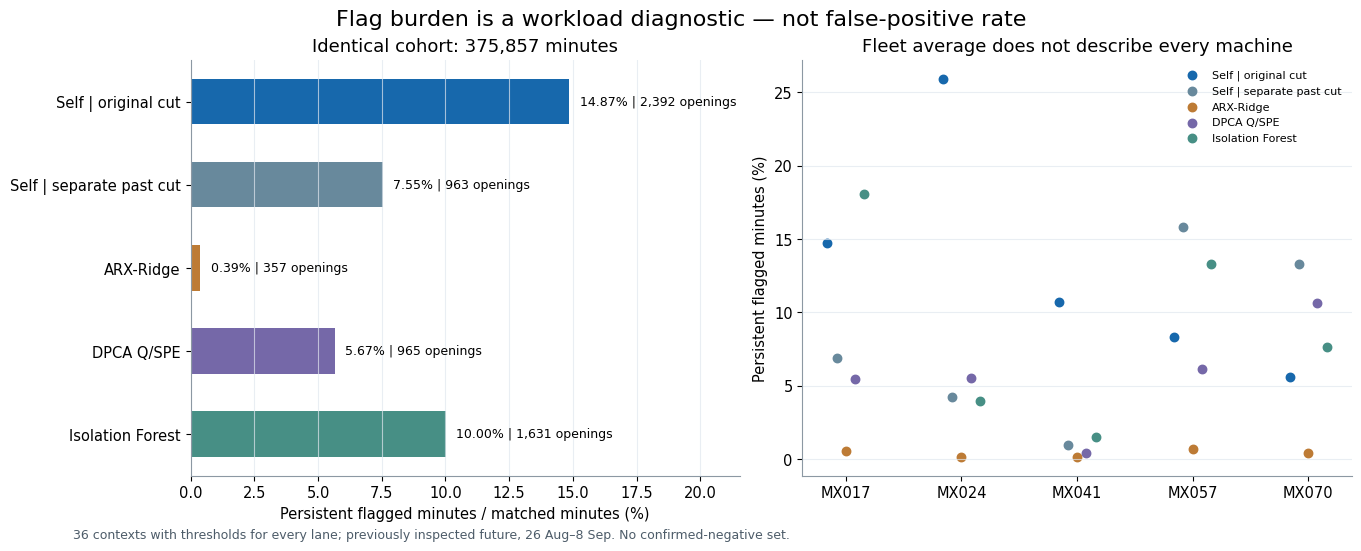

,machine,module,lane,rows,raw_flags,persistent_flags,persistent_pct,openings,qualified_days
0,017,1,self_legacy,17513,2876,2769,15.811112,26,14
1,017,1,self_separate,17513,2690,2645,15.103066,17,14
2,017,1,arx,17513,751,426,2.432479,100,14
3,017,1,dpca,17513,2571,1987,11.345857,153,14
4,017,1,iforest,17513,2333,2131,12.168104,50,14
...,...,...,...,...,...,...,...,...,...
245,080,8,self_legacy,16064,9,7,0.043576,1,13
246,080,8,self_separate,0,0,0,NaN,0,0
247,080,8,arx,0,0,0,NaN,0,0
248,080,8,dpca,0,0,0,NaN,0,0


In [7]:
display(viz.matched_burden(OUT))
display(t['burden'])

อ่านกราฟอย่างระวัง: เปอร์เซ็นต์ที่ต่ำกว่าหมายถึง flagged workload ต่ำกว่า ไม่ได้แปลว่าแม่นยำกว่า เพราะยังไม่มีชุด verified-normal negatives กราฟใช้เฉพาะ context ที่ทุก lane มี threshold และมีจำนวน matched rows เท่ากัน ช่วงเวลาของแต่ละเครื่องต่างกันตาม coverage เส้นในกราฟขวาจึงอธิบายความต่างของ burden ไม่ใช่ ranking ความเสี่ยงของเครื่อง

## 7. กรณีที่ยืนยันแล้ว: ตรวจช่วงเดิมได้ไหม และใครเป็น contributor

MX057/M1 29 ส.ค. 04:06–22:50 และ MX080/M6 7 ก.ย. 12:23:28–8 ก.ย. 00:00 เป็น owner-confirmed behavioral cases ยังไม่มี technician cause confirmation. Coverage ข้างล่างนับเฉพาะ matched qualified minutes ที่มี threshold จึงไม่ใช่ sensitivity บนทุก raw second เวลา decision เป็นปลายนาทีที่ window complete แล้ว ยังไม่รวมรอ worker fetch 5 นาทีหรือ network delay

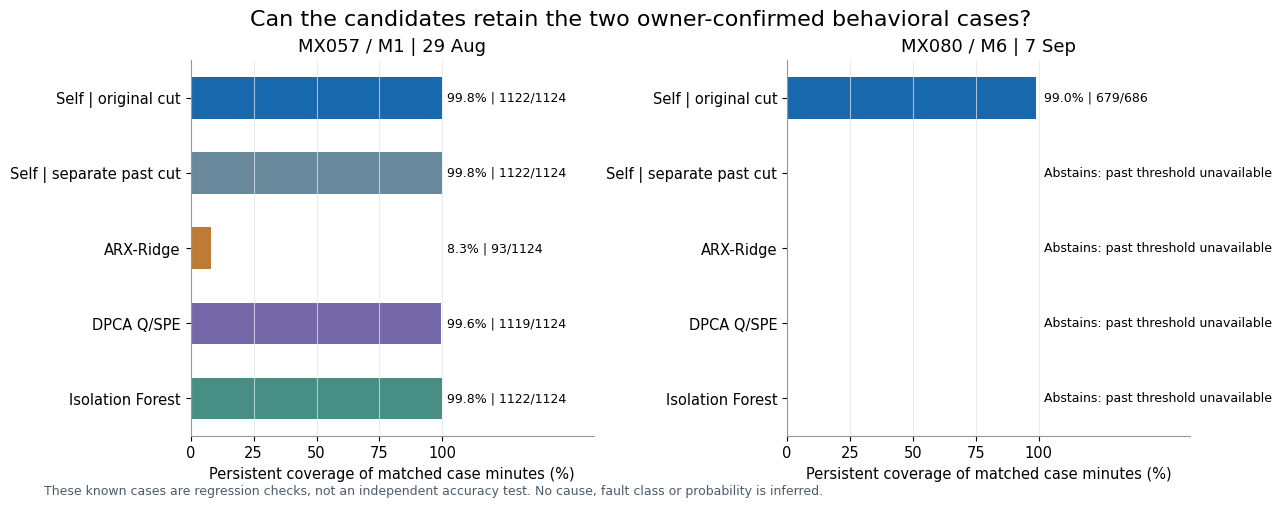

,machine,module,lane,case_start,case_end,matched_case_rows,supported_rows,persistent_rows,coverage_pct,first_flag_window,decision_time,diagnostic_delay_minutes
0,057,1,self_legacy,2026-08-29 04:06:00,2026-08-29 22:50:00,1124,1124,1122,99.822064,2026-08-29 04:08:00,2026-08-29 04:09:00,3.000000
1,057,1,self_separate,2026-08-29 04:06:00,2026-08-29 22:50:00,1124,1124,1122,99.822064,2026-08-29 04:08:00,2026-08-29 04:09:00,3.000000
2,057,1,arx,2026-08-29 04:06:00,2026-08-29 22:50:00,1124,1124,93,8.274021,2026-08-29 04:08:00,2026-08-29 04:09:00,3.000000
3,057,1,dpca,2026-08-29 04:06:00,2026-08-29 22:50:00,1124,1124,1119,99.555160,2026-08-29 04:08:00,2026-08-29 04:09:00,3.000000
4,057,1,iforest,2026-08-29 04:06:00,2026-08-29 22:50:00,1124,1124,1122,99.822064,2026-08-29 04:08:00,2026-08-29 04:09:00,3.000000
5,080,6,self_legacy,2026-09-07 12:23:28,2026-09-08 00:00:00,686,686,679,98.979592,2026-09-07 12:26:00,2026-09-07 12:27:00,3.533333
6,080,6,self_separate,2026-09-07 12:23:28,2026-09-08 00:00:00,686,0,0,NaN,NaT,NaT,NaN
7,080,6,arx,2026-09-07 12:23:28,2026-09-08 00:00:00,686,0,0,NaN,NaT,NaT,NaN
8,080,6,dpca,2026-09-07 12:23:28,2026-09-08 00:00:00,686,0,0,NaN,NaT,NaT,NaN
9,080,6,iforest,2026-09-07 12:23:28,2026-09-08 00:00:00,686,0,0,NaN,NaT,NaT,NaN


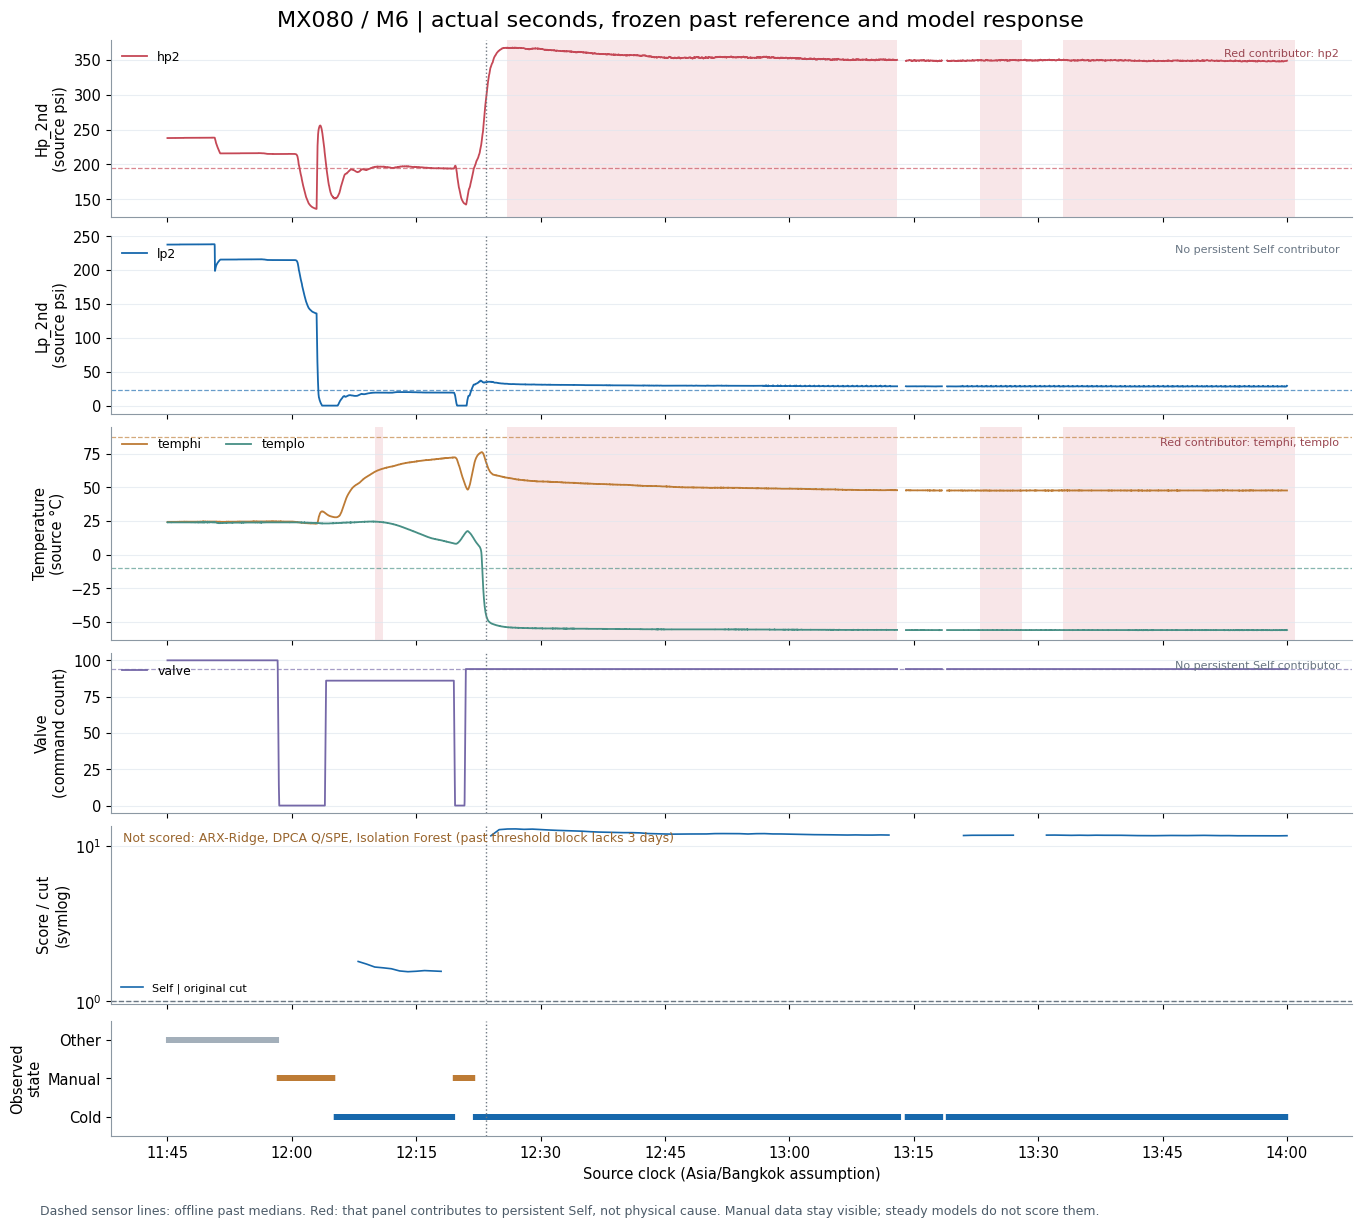

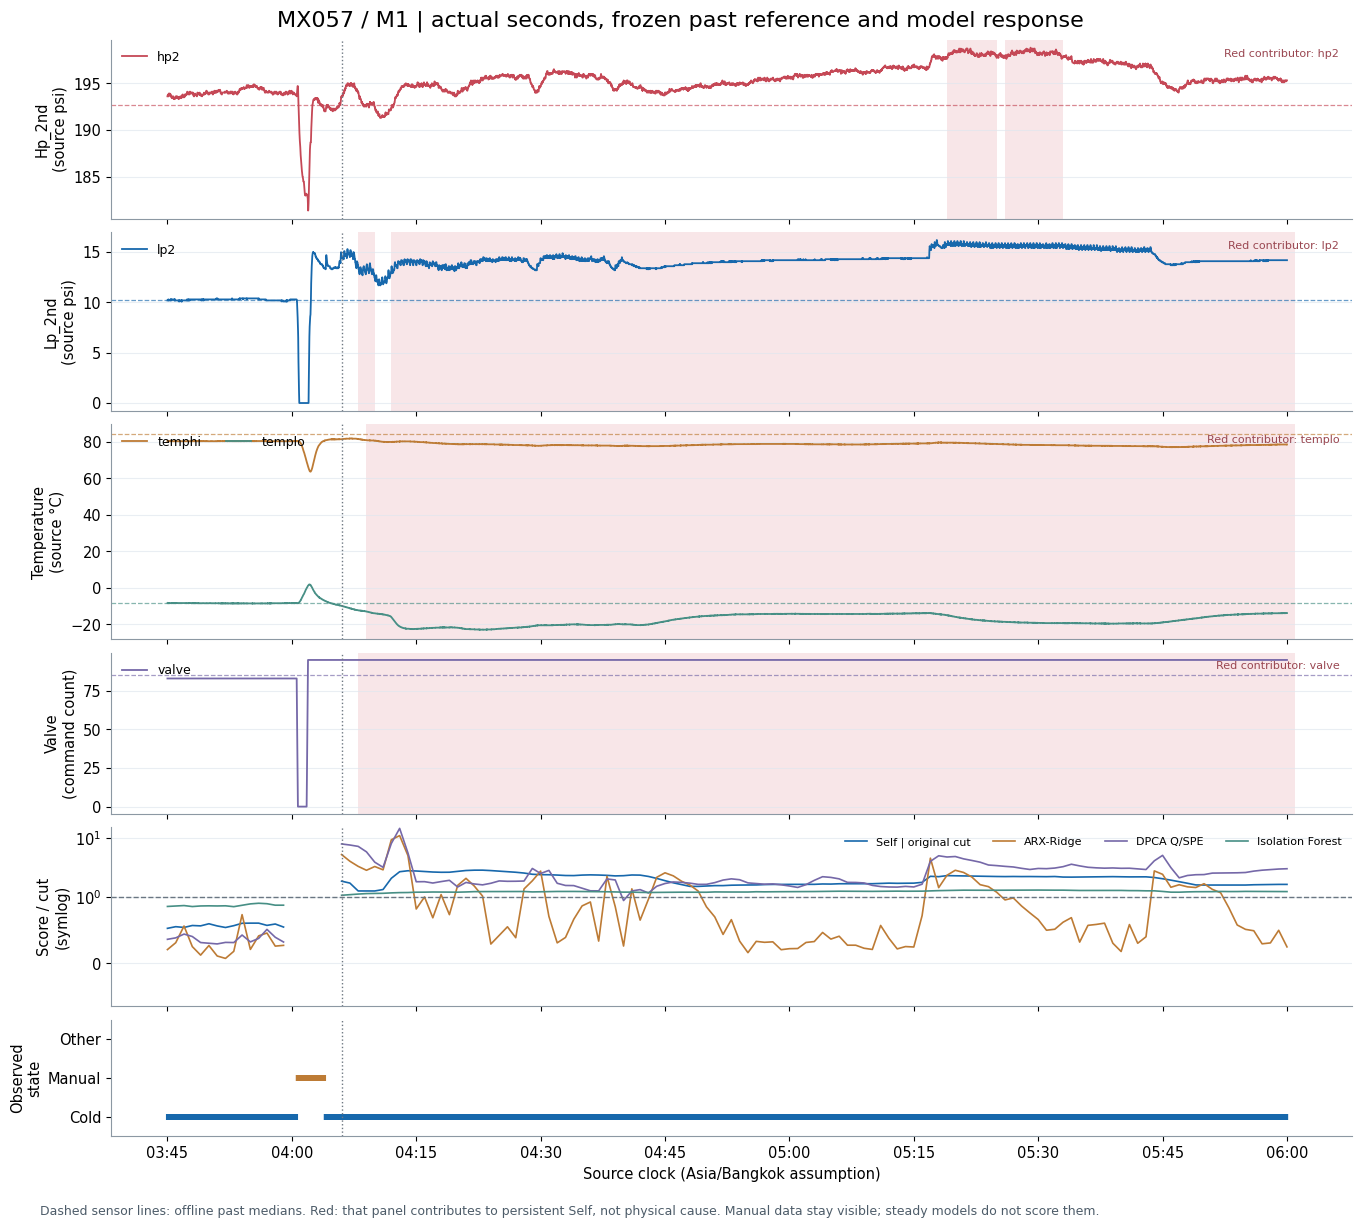

In [8]:
display(viz.case_comparison(OUT))
display(t['cases'])
display(viz.case_timeline(OUT,'080'))
display(viz.case_timeline(OUT,'057'))

**MX080/M6:** ในวันที่ 22–25 ส.ค. มี matched Cold data เพียงสองวัน (2,289 นาที) จึงไม่ผ่านขั้นต่ำสามวันสำหรับ threshold ของ ML/Self-separate lanes แม้จำนวนแถวจะมากพอ ช่องนี้ต้องอ่านว่า **abstain เพราะไม่มี threshold ที่ qualified** ไม่ใช่ score=0 หรือโมเดลตรวจไม่พบ Self-original ในกราฟเป็น offline reference probe ไม่ใช่การอนุมัติ Profile ที่ review-required

เส้น sensor เป็นค่ารายวินาทีจริง ไม่ interpolate และแยก pressure/temperature/Valve คนละแกน เส้นประเป็น offline fit median. พื้นแดงเกิดเฉพาะ panel ที่มี stored feature ข้าม Self threshold พร้อม global persistence จึงไม่ทำให้ Valve ดูผิดปกติเพียงเพราะ temperature เป็นตัวดัน global score Manual/status strip ยังอยู่เพื่ออ่านลำดับเหตุการณ์ แต่ temporal association ไม่ใช่ข้อยืนยันว่า manual ทำให้เครื่องเสีย

## 8. ทดสอบการถ่ายโอนระหว่างเครื่อง และต้นทุน

แต่ละ fold ฝึก shared model โดยตัด held machine ออก แล้วสร้าง threshold จาก past block ของ held machine เท่านั้น ทุก fold ยังคง local reference ของเครื่องนั้นอยู่เพื่อเลียนแบบ target adaptation. ต้องอ่าน worst-machine/context ด้วย ไม่ใช่ค่า fleet เฉลี่ยอย่างเดียว ผลนี้ยังไม่ทดสอบ transfer ไป new model of machine หรือ SV/mode ที่ไม่เคย qualified

In [9]:
display(t['lomo'].groupby(['machine','lane']).agg(rows=('rows','sum'), persistent=('persistent_flags','sum'), openings=('openings','sum')))
print('Batch model scoring seconds:', t['summary']['model_score_seconds'])
print('Measured seconds / 1000 matched rows:', t['summary']['seconds_per_1000_matched_rows'])
print('Artifact reload max |difference|:', t['summary']['artifact_reload_max_abs_error'])
print('Actual source / runtime window comparisons:', t['summary']['strict_actual_source_window_comparisons'])

rows  persistent  openings
machine lane                                       
017     arx            122724         660       164
        dpca           122724       10213       419
        iforest        122724       21926       857
        self_legacy    122724       18052       726
        self_separate  122724        8432       305
024     arx             97523         146        58
        dpca            97523        5387       485
        iforest         97523        4343       443
        self_legacy     97523       25277      1317
        self_separate   97523        4135       359
029     arx                 0           0         0
        dpca                0           0         0
        iforest             0           0         0
        self_legacy     30821       12245       489
        self_separate       0           0         0
057     arx             48477         435       103
        dpca            48477        3804        78
        iforest         48477        6140       279
        self_legacy     48477        4044        52
        self_separate   48477        7669       101
070     arx             57633         206        30
        dpca            57633        3741       153
        iforest         57633        5282       187
        self_legacy     57633        3208        58
        self_separate   57633        7664       170

Batch model scoring seconds: 40.97024109999984
Measured seconds / 1000 matched rows: 0.027184242057099073
Artifact reload max |difference|: 0.0
Actual source / runtime window comparisons: 336


ตัวเลข latency มาจาก batch บนคอมเครื่องนี้ ไม่ใช่ benchmark Server หรือ live p95 end-to-end: ยังต้องตรวจ MySQL read, checkpoint, late arrival, alert bridge และ UI บน target staging อีกครั้ง โมเดล sklearn ไม่มี epoch แบบ LSTM; Ridge/DPCA แก้ optimization/SVD และ IF ใช้จำนวน trees ไม่ควรถาม epoch เพื่อตัดสินว่าฝึกพอหรือไม่

## 9. วิธีที่เลือก และสิ่งที่จะปรับ Auto-Calibration

**เลือก local frozen robust-z + 3 adjacent-minute persistence เป็น primary ในตอนนี้** โดยคง Machine × Module × qualified state/SV context เหตุผลคือมีหลักฐานระดับค่าตัวเองชัด อธิบาย contributor ได้ และไม่ปล่อยให้ persistent plateau ถูก prediction จากอดีตระยะสั้นกลืนเป็นปกติ ยังไม่มี independently reviewed incremental benefit หรือ healthy negatives มากพอจะยกระดับ ARX/DPCA/IF ให้เปิด alert

การทดลองนี้ทำ reference screening และ train-only artifacts ใช้งานได้จริงใน local research path แล้ว แต่ **ยังไม่ได้เปลี่ยน Auto-Calibration registry/runtime** ทิศทางที่ควรทำต่อคือแยก data quality ออกจาก operating phase, เก็บ manual events, ตรวจ stable reference period ก่อน approve และเรียนรู้ startup/settling จากหลายครั้งที่มี onset จริง ไม่ใช้ fixed 20-minute suppression หรือ re-zero Profile ตาม plateau ล่าสุดโดยอัตโนมัติ

ARX ช่วยเป็น dynamic evidence, DPCA ช่วย covariance/lag evidence, IF เป็น novelty comparator: ทั้งสามเก็บเป็น non-voting shadow เพื่อให้ช่าง review ช่วงที่เพิ่มจาก Self LSTM ไม่ได้ train ในรอบนี้: ความซับซ้อนและข้อมูล unlabeled เพิ่มไม่ได้แก้ปัญหา reference contamination เอง จึงยังไม่มีเหตุผลจากผลทดลองนี้ให้แทน primary

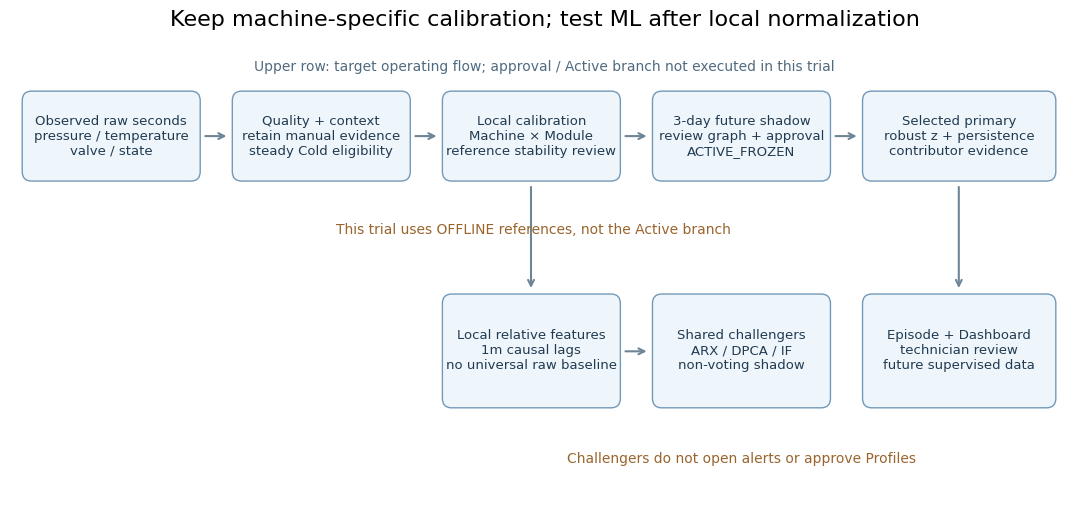

In [10]:
display(viz.workflow(OUT))

## 10. QA และวิธีทำซ้ำ

Unit tests ตรวจ split isolation, future mutation ไม่เปลี่ยน Profile/threshold, insufficient reference, lag reset และ `>=` persistence Actual source comparison ใช้ตัวสร้าง window ของระบบจริงใน clean/manual/source boundaries; model reload ต้องให้คะแนนต่างกัน = 0 Source files ไม่ถูกแก้ และมี SHA-256 ของ input inventory, protocol, code, models และตารางผล

Rebuild จาก project root:

```bash
python -X utf8 -m notebooks.support.local_profile_model_selection ingest --raw-root <raw_parquet_root>
python -X utf8 -m notebooks.support.local_profile_model_selection benchmark --raw-root <raw_parquet_root>
python -X utf8 -m pytest notebooks/support/test_local_profile_model_selection.py notebooks/support/test_october_three_machine_calibration.py -q
```

หากยังไม่มี cache ของ October ZIP ให้รัน Notebook 08K/intake ของมันก่อน การสร้าง raw cache ยังใช้ timestamp precision normalization และ strict gate เหมือนเดิม อย่าโหลด joblib จากแหล่งที่ไม่ไว้วางใจ; ใช้ artifact ที่ตรวจ hash และ sklearn version ตรงกับ manifest

In [11]:
import hashlib
failures=[]
for name, expected in t['summary']['hashes'].items():
    with (OUT/name).open('rb') as stream:
        actual=hashlib.file_digest(stream,'sha256').hexdigest()
    if actual != expected: failures.append(name)
assert not failures, failures
print('Artifact hash QA: PASS')
print(*t['summary']['limits'], sep=chr(10))

Artifact hash QA: PASS
No verified healthy negative set: flag burden is not false-positive rate.
Previously inspected cases and history: diagnostic regression, not independent model accuracy.
Self legacy and separate-calibration policies are intentionally distinct.
Adapted LOMO allows held-unit past profiles and calibration, not zero-shot generalization.
No transition-response model fitted; manual evidence retained, steady models abstain there.
No genuine Active or three-day registry lifecycle was executed; no approval/DB/Server writes.
One-minute means do not preserve all second-level transients; source-second evidence is separate.


## แหล่งอ้างอิงและเหตุผลการเลือกวิธี

รายละเอียดงานวิจัยพร้อมขอบเขตที่อ่านได้อยู่ใน `research/HT9046MX_CONTROL_STATE_AND_ANOMALY_RESEARCH_20261001.md` ผลของ papers ไม่ได้ถูกถือเป็นผลของ HT9046MX ของเรา

- [Ku et al. (1995), DPCA](https://doi.org/10.1016/0169-7439(95)00076-3): ใช้แนว lag-embedded relationship monitoring ไม่ได้ implement fault model bank ของงานเดิม
- [Yan et al. (2014), ARX + SVM](https://doi.org/10.1016/j.enbuild.2014.05.049): ใช้แนว predictive residual แต่ไม่ใช้ supervised fault SVM เพราะไม่มี fault labels
- [Farouq et al. (2022), unit/subfleet monitoring](https://doi.org/10.1016/j.eswa.2022.116864): รองรับการคง local reference แทน raw global baseline ไม่ได้ให้ conformal guarantee กับข้อมูล drift ของเรา
- [Ridge API](https://scikit-learn.org/1.8/modules/generated/sklearn.linear_model.Ridge.html), [PCA API](https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.PCA.html), [IsolationForest API](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.IsolationForest.html): อ้าง parameter/score semantics; รันจริง sklearn 1.8.0 ตาม manifest

บทสรุปของงานนี้เป็นการเลือกวิธีที่เหมาะกับหลักฐานที่มีตอนนี้ ไม่ใช่การอ้างว่า model หนึ่งดีที่สุดสำหรับ fault ทุกชนิด